In [1]:
import sys, cv2, torch, easyocr, paddle, paddleocr

print("Python", sys.version.split()[0])
print("OpenCV", cv2.__version__)
print("PyTorch", torch.__version__)
print("EasyOCR", easyocr.__version__)
print("PaddlePaddle", paddle.__version__)
print("PaddleOCR", paddleocr.__version__)

c:\D into C(06-22-2026_18-36)\my_files\university\4.1\ШІ\лаб_3\AI_lab3_text_recognition\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
c:\D into C(06-22-2026_18-36)\my_files\university\4.1\ШІ\лаб_3\AI_lab3_text_recognition\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.


Python 3.12.13
OpenCV 4.10.0
PyTorch 2.15.0+cpu
EasyOCR 1.7.2
PaddlePaddle 3.3.1
PaddleOCR 3.4.1


## 1. Імпорт бібліотек

In [2]:
import os, re, time, hashlib, unicodedata, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import requests
from PIL import Image, ImageDraw, ImageFont
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

## 2. Персональні параметри та налаштування

In [3]:
STUDENT = "Твердун Т.А."
VARIANT = 11
STUDENT_ID = 44
SEED = 1000 * VARIANT + STUDENT_ID
rng = np.random.default_rng(SEED)

FONTS = [
    "C:/Windows/Fonts/arial.ttf",
    "C:/Windows/Fonts/times.ttf",
    "C:/Windows/Fonts/calibri.ttf",
    "C:/Windows/Fonts/georgia.ttf",
    "C:/Windows/Fonts/verdana.ttf",
    "C:/Windows/Fonts/tahoma.ttf",
]

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def stamp(ax, title):
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

print("SEED =", SEED)

SEED = 11044


## 3. Синтетичний набір даних

### 3.1. Завантаження тексту твору

In [4]:
resp = requests.get(
    "https://uk.wikisource.org/w/index.php",
    params={"title": "Лісова пісня", "action": "raw"},
    headers={"User-Agent": "lab3-ocr-student"},
    timeout=30,
)
resp.raise_for_status()
raw = resp.text

print("Characters loaded:", len(raw))
print(raw[:1500])

Characters loaded: 88563
{{заголовок
 | назва      = Лісова пісня
 | автор      = Леся Українка
 | перекладач = 
 | секція     = 
 | попередня  = 
 | наступна   = 
 | рік        =1911 
 | примітки   = 
}}
<poem>
ЛІСОВА ПІСНЯ
Драма-феєрія в 3-х діях
 
СПИС ДІЯЧІВ "ЛІСОВОЇ ПІСНІ"
 
ПРОЛОГ
 
"Той, що греблі рве". 	Русалка. 
Потерчата (двоє).	        Водяник.
 
ДІЯ І
 
Дядько Лев. 	      Перелесник. 
Лукаш. 	              Пропасниця (без мови). 
Русалка. 	              Потерчата. 
Лісовик. 	              Куць.
Мавка.
 
ДІЯ II
 
Мати Лукашева.	Килина.
Лукаш.	                 Русалка.
Дядько Лев.                "Той, що в скалі
Мавка.                        сидить".
Русалка Польова.     Перелесник.
 
ДІЯ III
 
Мавка.                            Хлопчик.
Лісовик.                          Лукаш.
Куць.                               Діти Килинині
Злидні.                            (без мови).
Мати Лукашева.             Доля.
Килина.                           Перелесник.
 
ПРОЛОГ
 
Старезний, густ

### 3.2. Очищення тексту

In [5]:
text = raw.split("<poem>")[1].split("</poem>")[0]
text = text[text.index("Старезний"):]

def is_speaker(line):
    words = re.sub(r"[^\w\s]", "", line).split()
    singles = sum(len(w) == 1 for w in words)
    return singles >= 3 and all(len(w) <= 2 for w in words)

kept = [l for l in text.splitlines() if not is_speaker(l) and not l.strip().isupper()]
text = " ".join(kept)
text = re.sub(r"\([^)]*\)", " ", text)
text = " ".join(text.split())

print("Characters after cleaning:", len(text))
print(text[:800])

Characters after cleaning: 68044
Старезний, густий, предковічний ліс на Волині. Посеред лісу простора галява з плакучою березою і з великим прастарим дубом. Галява скраю переходить в куп'я та очерети, а в одному місці в яро-зелену драговину - то береги лісового озера, що утворилося з лісового струмка. Струмок той вибігає з гущавини лісу, впадає в озеро, потім, по другім боці озера, знов витікає і губиться в хащах. Саме озеро - тиховоде, вкрите ряскою та лататтям, але з чистим плесом посередині. Містина вся дика, таємнича, але не понура, - повна ніжної, задумливої поліської краси. Провесна. По узліссі і на галяві зеленіє перший ряст і цвітуть проліски та сон-трава. Дерева ще безлисті, але вкриті бростю, що от-от має розкритись. На озері туман то лежить пеленою, то хвилює од вітру, то розривається, одкриваючи блідо-блакитну


### 3.3. Поділ на речення

In [6]:
sentences = re.split(r'(?<=[.!?…])\s+|(?<=[.!?…]")\s+', text)
sentences = [s.lstrip(" ,;:-") for s in sentences]
corpus = list(dict.fromkeys(s for s in sentences if 20 <= len(s) <= 70))

with open("corpus.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(corpus))

print("Sentences total:", len(sentences))
print("Sentences in corpus (20-70 chars):", len(corpus))
for s in corpus[:10]:
    print(s)

Sentences total: 1783
Sentences in corpus (20-70 chars): 803
Старезний, густий, предковічний ліс на Волині.
Дерева ще безлисті, але вкриті бростю, що от-от має розкритись.
З гір на долину біжу, стрибаю, рину!
Чого ти тута блудиш?
Чого зо сну нас будиш?
Чого ж ти тут шугаєш?
Зіб'ю всю вашу воду, таки знайду ту вроду!
Печера в нас маленька, що збудувала ненька.
Убога наша хатка, бо в нас немає татка...
Нехай до мене зрине!


### 3.4. Вибір 40 речень

In [7]:
N_LINES = 40
lines = [str(s) for s in rng.choice(corpus, size=N_LINES, replace=False)]

print("Selected lines:", len(lines))
for s in lines:
    print(s)

Selected lines: 40
Який-бо ти, дідусю, став суворий!
Прохолодитись треба.
Хай Змія-цариця мене скарає, якщо се неправда!
Вже й сон-трава перецвітати стала.
Я ледь що вибрався живий на берег, і рибу розгубив...
Самій увечері в сій пущі сумно.
Мені здається, що жила я завжди...
В очеретах заблимали два бродячі вогники.
Я міркував би, що вже б тобі не тра верби на зиму.
Ти б іще зібрав сюди усіх відьом із лісу.
Якби ж воно такеє говорило, що тямить, ну, то й слухав би, а то...
Ви ж про Царівну мали.
Я не маю сили покинути її...
Чи бач, як знітилась невірна пара, відьомський накоренок!
Ні, се так добре - умерти, як летюча зірка...
"Той, що в скалі сидить" виходить і подається до Мавки.
бач, вона така суха, і все рипить, все згадує про зиму...
Перелесник здригнувся, прудким рухом кинувся геть і зник у лісі.
Вже з вирію поприлітали гості.
Ну, я піду - управлюся тим часом з дробиною.
Відай, ви, дядьку, щось тут проминули.
Чи у людей паруються надовго?
Дяка щирая тобі, ніченько-чарівниченько, 

### 3.5. Малювання рядка тексту

Image shape (height, width): (54, 528)


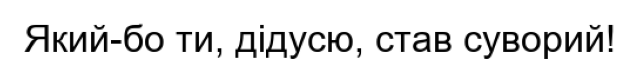

In [8]:
def render_line(text, font_path, size=32, pad=12):
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

example = render_line(lines[0], FONTS[0])
print("Image shape (height, width):", example.shape)

plt.figure(figsize=(8, 1))
plt.imshow(example, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

### 3.6. Нерівне освітлення

level  0 %: right edge background = 255
level 15 %: right edge background = 216
level 30 %: right edge background = 178
level 45 %: right edge background = 140
level 60 %: right edge background = 102
level 75 %: right edge background = 63


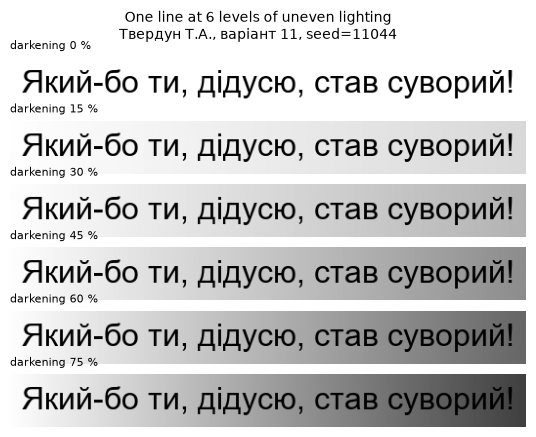

In [9]:
LEVELS = [0, 15, 30, 45, 60, 75]

def degrade(img, level):
    h, w = img.shape
    light = np.linspace(1.0, 1.0 - level / 100, w)
    out = img.astype(np.float32) * light
    return np.clip(out, 0, 255).astype(np.uint8)

for lvl in LEVELS:
    print(f"level {lvl:2d} %: right edge background = {degrade(example, lvl)[0, -1]}")

fig, axes = plt.subplots(len(LEVELS), 1, figsize=(8, 0.8 * len(LEVELS)))
for ax, lvl in zip(axes, LEVELS):
    ax.imshow(degrade(example, lvl), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"darkening {lvl} %", fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"One line at {len(LEVELS)} levels of uneven lighting\n"
             f"{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig0_samples.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.7. Генерація набору

In [ ]:
FACTOR = "light"

records = []
for i, sentence in enumerate(lines):
    font = FONTS[i % len(FONTS)]
    size = int(rng.integers(22, 36))
    clean = render_line(sentence, font, size=size)
    for lvl in LEVELS:
        path = f"data/{i:03d}_{FACTOR}_{lvl}.png"
        cv2.imwrite(path, degrade(clean, lvl))
        records.append({"id": i, "level": lvl, "path": path, "gt": sentence,
                        "font": os.path.basename(font), "size": size})

ds = pd.DataFrame(records)
print("Images saved:", len(ds))
ds.head(8)

Images saved: 240


,id,level,path,gt,font,size
0,0,0,data/000_light_0.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
1,0,15,data/000_light_15.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
2,0,30,data/000_light_30.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
3,0,45,data/000_light_45.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
4,0,60,data/000_light_60.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
5,0,75,data/000_light_75.png,"Який-бо ти, дідусю, став суворий!",arial.ttf,33
6,1,0,data/001_light_0.png,Прохолодитись треба.,times.ttf,26
7,1,15,data/001_light_15.png,Прохолодитись треба.,times.ttf,26


### 3.8. Еталон і хеш SHA-256

In [11]:
ds.to_csv("data/ground_truth.csv", index=False, lineterminator="\n")

with open("data/ground_truth.csv", "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()

print("Ground truth rows:", len(ds))
print("SHA-256:", sha)

Ground truth rows: 240
SHA-256: bb4adf6309f3819522854306055ef5b6cb151dd4dcf21b89cf1da4d77c08c667
